# 511 keV Residual Analysis

This notebook applies the residual-analysis tools to the observed and fitted disk-scale histograms. It prepares a common mask and projections, then compares raw, Pearson, and fractional residual views


In [1]:
%load_ext autoreload
%autoreload 2

# Handle filesystem paths in a platform-independent way.
from pathlib import Path
import sys # Access the Python import path.

working_dir = Path.cwd()
repo_root = (
    working_dir.parent
    if working_dir.name == "notebooks"
    else working_dir
)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

## Setup and imports

Set the workflow path and import the analysis, plotting, and histogram tools.


In [2]:
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals

from histpy import Histogram
import numpy as np
from IPython.display import display


## Load the observed and expected histograms

Both products are read from the saved disk-scale HDF5 file.


In [3]:
residual_dir = repo_root / "data" / "residual"
disk_scale_file = residual_dir / "04_511_disk_scale_residual_products.hdf5"

In [4]:
observed_disk_scale = Histogram.open(
    disk_scale_file,
    name="observed",
)

expected_disk_scale = Histogram.open(
    disk_scale_file,
    name="total_expectation",
)

## Initialize the analysis and inspect the mask

The analysis validates the histogram pair and reports bins excluded by its numerical-floor mask.


In [5]:
residual_analysis = ResidualAnalysis(
    observed_disk_scale,
    expected_disk_scale,
)

In [6]:
residual_analysis.mask_report

{'total_bins': 184320,
 'valid_bins': np.int64(175104),
 'excluded_bins': np.int64(9216),
 'observed_counts_excluded': np.float64(0.0),
 'minimum_expected': <Quantity 2.25381475e-308>,
 'minimum_retained_expected': <Quantity 0.00120618>}

## Prepare the supported projections

The projection keys below are the names accepted by the residual and plotting methods.


In [7]:
# Build the projections and display their available names.
projected_data = residual_analysis.projected_data()
list(projected_data.keys())

['Phi_projection',
 'Chi_projection',
 'Psi_projection',
 'PsiChi_projection',
 'Phi_Chi_projection',
 'Phi_Psi_projection',
 'Phi_PsiChi_projection']

In [8]:
# Build and display the summary statistics table.
display(residual_analysis.statistics_table())

,Statistic,Value,Interpretation
0,Valid CDS bins,175104,Bins included in the global comparison.
1,Excluded CDS bins,9216,Numerical-floor bins removed by the mask.
2,Observed counts in valid bins,1576953.0,Observed events included in the comparison.
3,Expected counts in valid bins,1576956.438906,Model-predicted events in the same bins.
4,Pearson chi-square (χ²),39785.025042,Global sum of squared Pearson residuals.
5,Mean Pearson contribution per valid bin,0.227208,Descriptive average; not a reduced chi-square.
6,Poisson deviance,27285.937041,Global likelihood-based discrepancy from the m...
7,Global goodness-of-fit p-value,Not calibrated,Requires a justified reference distribution ac...


## Check the one-dimensional Phi projection

First confirm the residual histogram has the expected axis and bin shape.


In [9]:
# Calculate the raw residual for the Phi projection.
phi_raw_residual = residual_analysis.residual_function(
    "Phi_projection",
    residual_type="raw",
)

# Show the residual histogram's axis labels and shape.
print("Axes:", phi_raw_residual.axes.labels)
print("Shape:", phi_raw_residual.shape)

Axes: ['Phi']
Shape: (60,)


## One-dimensional Phi diagnostics

Compare the three residual definitions for the same projection.


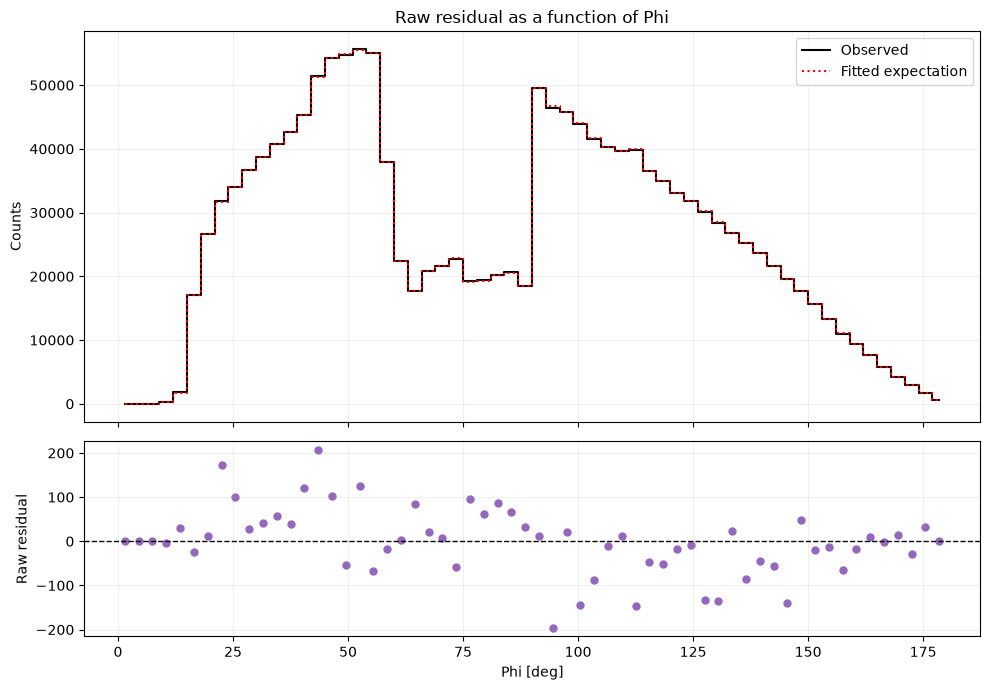

In [10]:
# Create the plotting helper from the existing analysis.
residual_plots = PlottingResiduals(residual_analysis)

# Plot observed and expected counts with the raw residual for Phi.
phi_raw_figure = residual_plots.plot(
    "Phi_projection",
    residual_type="raw",
)

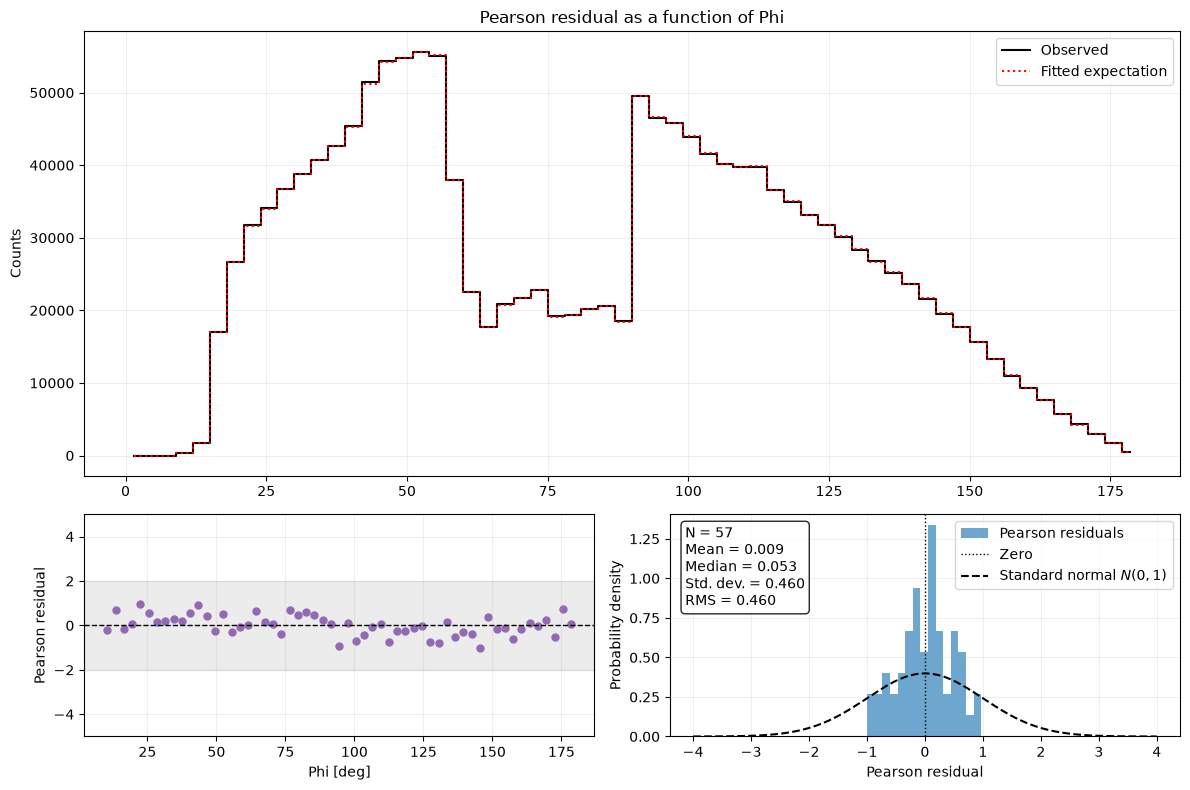

In [11]:
# Plot the Pearson residual diagnostic for the Phi projection.
phi_pearson_figure = residual_plots.plot(
    "Phi_projection",
    residual_type="pearson",
)

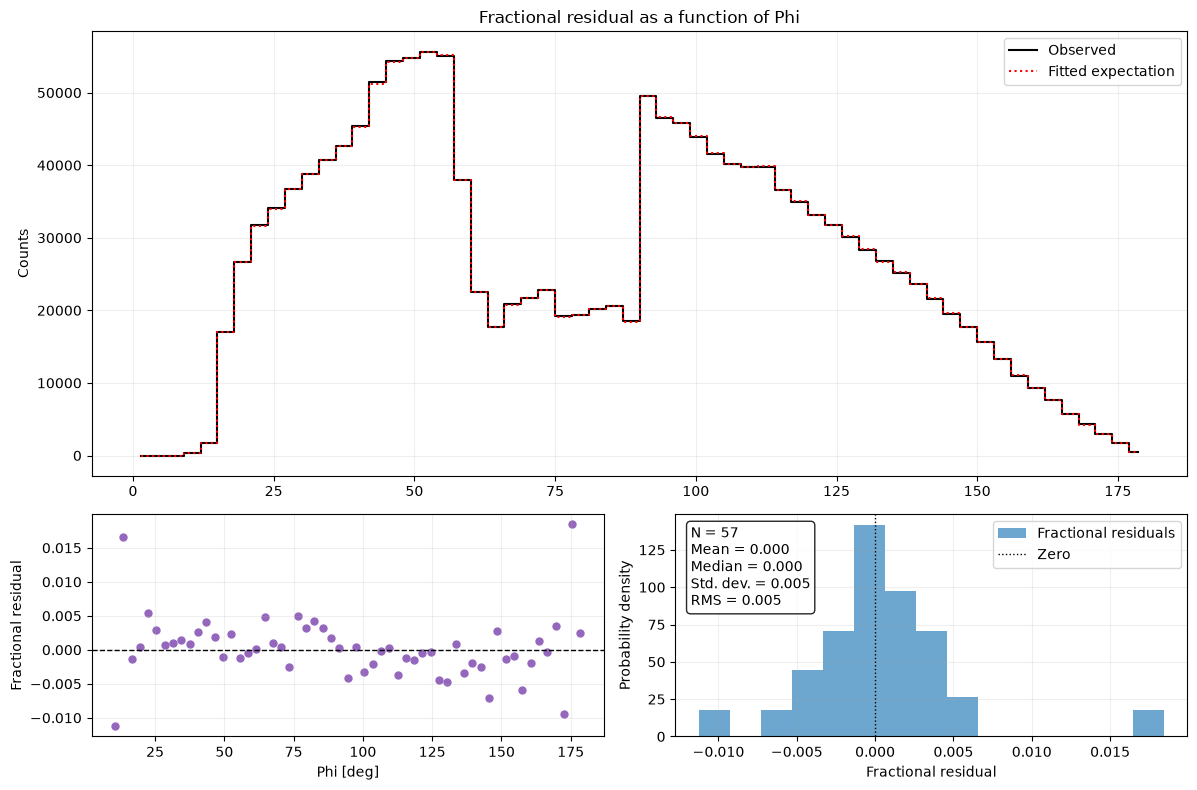

In [12]:
# Plot the fractional residual diagnostic for the Phi projection.
phi_fractional_figure = residual_plots.plot(
    "Phi_projection",
    residual_type="fractional",
)

## Rectangular Phi–Chi and Phi–Psi diagnostics

These calls display both paired maps.


/Users/maura/Documents/COSI/data-challenge-4/workflow/src/plot_residuals.py:512: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()


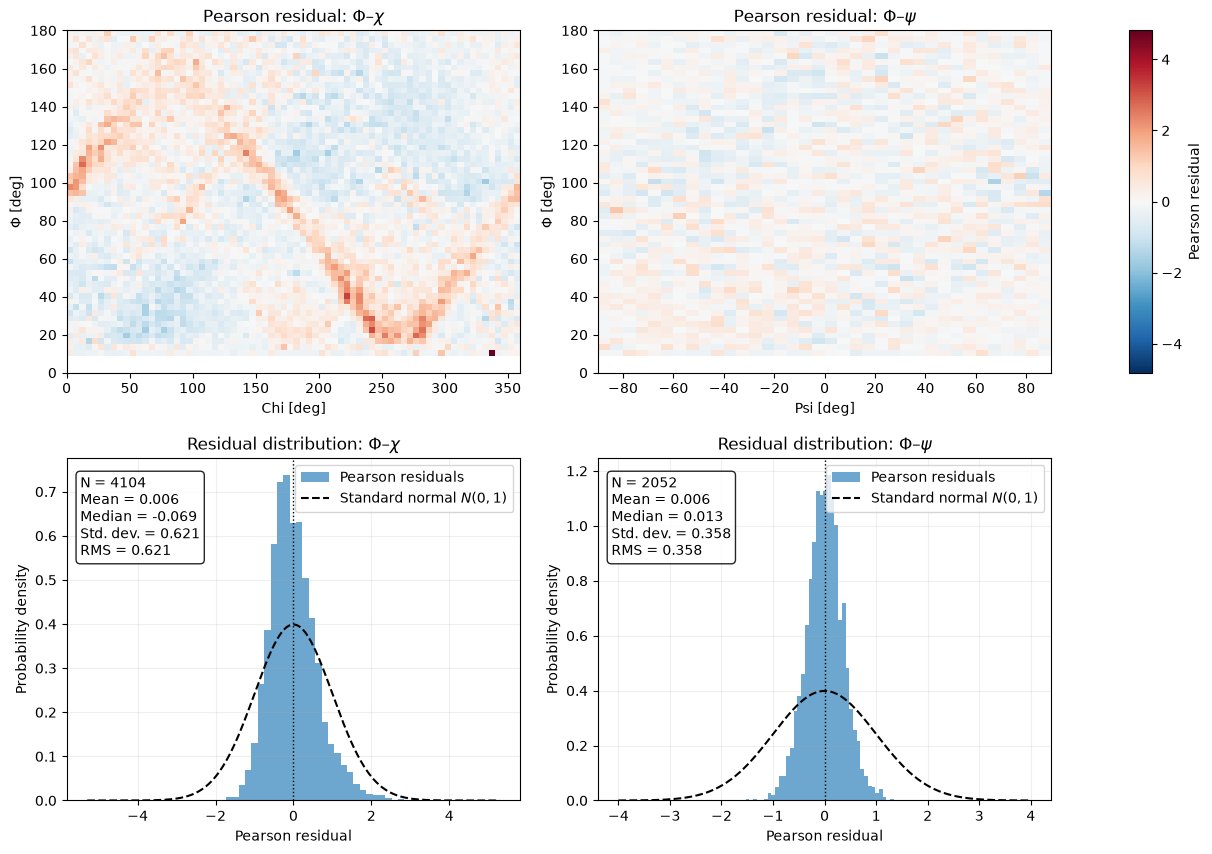

In [13]:
# Plot the Pearson residual diagnostic for the Phi–Chi projection.
phi_chi_pearson_figure = residual_plots.plot(
    "Phi_Chi_projection",
    residual_type="pearson",
)

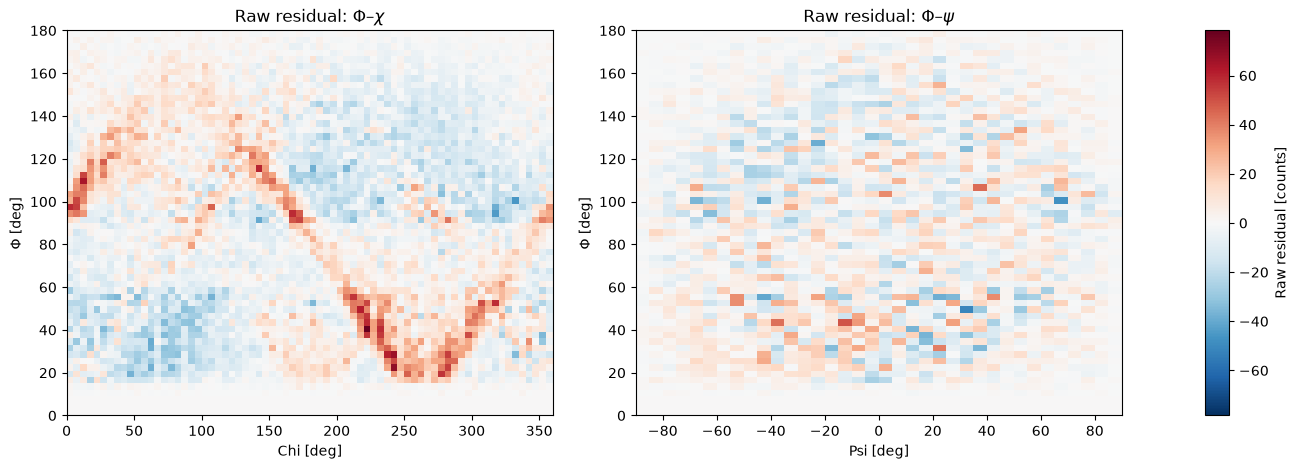

In [14]:
# Plot raw residuals for the paired 2D projections.
phi_2d_raw_figure = residual_plots.plot(
    "Phi_Chi_projection",
    residual_type="raw",
)

## HEALPix PsiChi diagnostics

The first group is integrated over Phi; the second examines one selected Phi bin.


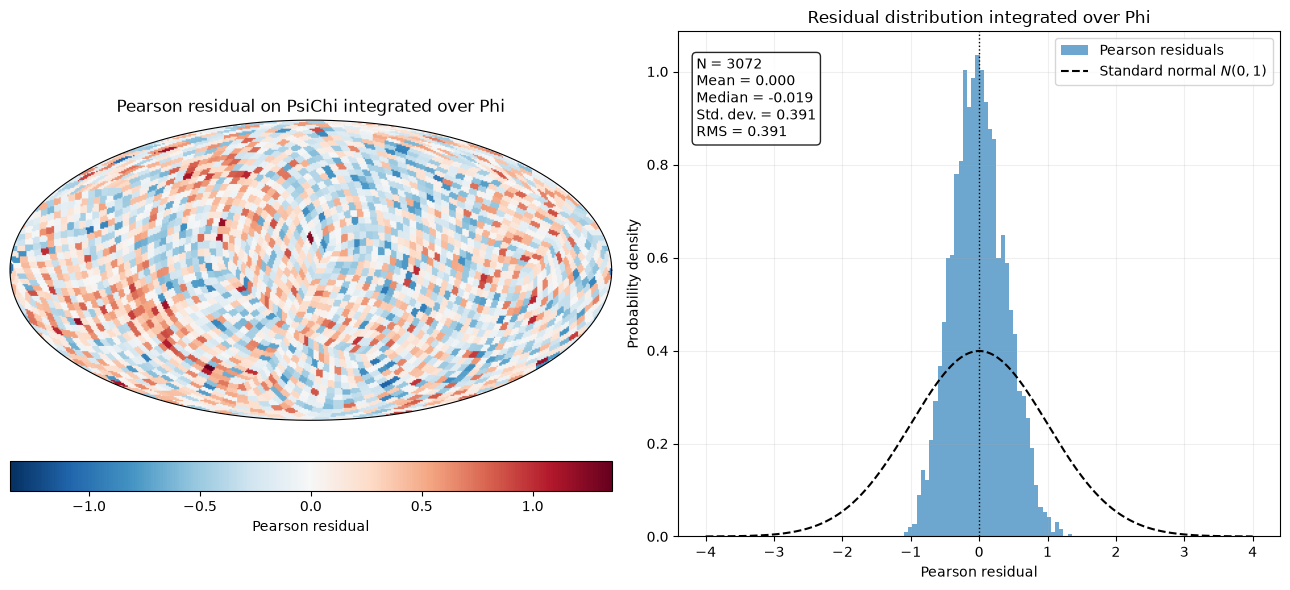

In [15]:
# Plot Pearson residuals for the PsiChi projection integrated over Phi.
psichi_pearson_figure = residual_plots.plot(
    "PsiChi_projection",
    residual_type="pearson",
)

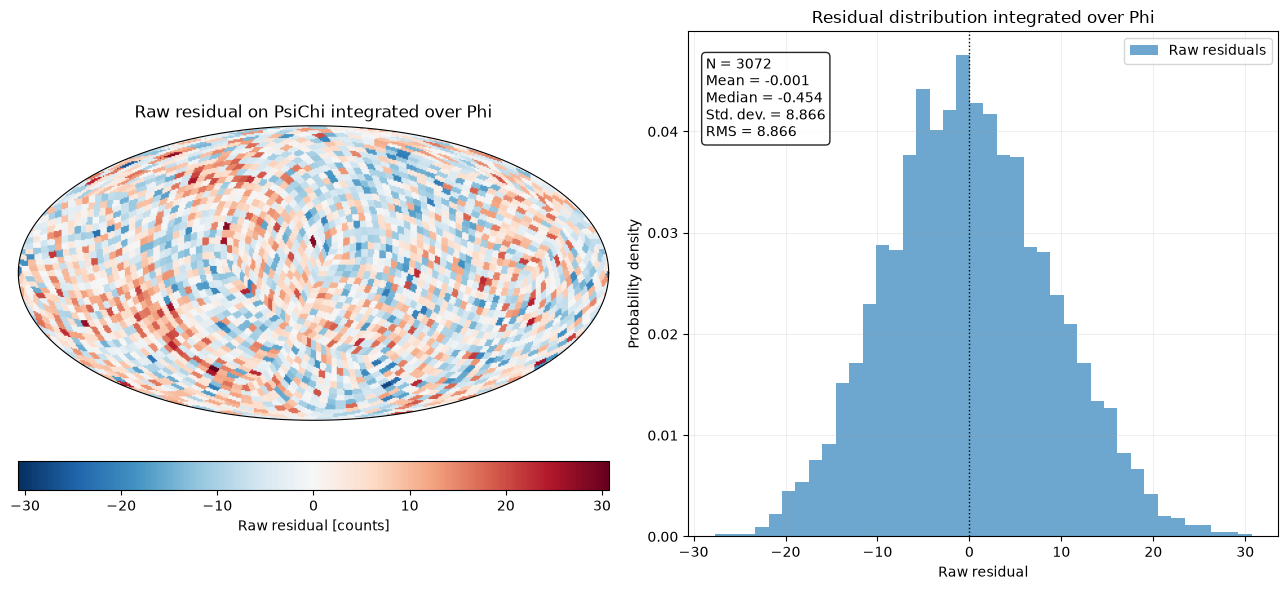

In [16]:
# Plot raw residuals for the full PsiChi projection integrated over Phi.
psichi_raw_figure = residual_plots.plot(
    "PsiChi_projection",
    residual_type="raw",
)

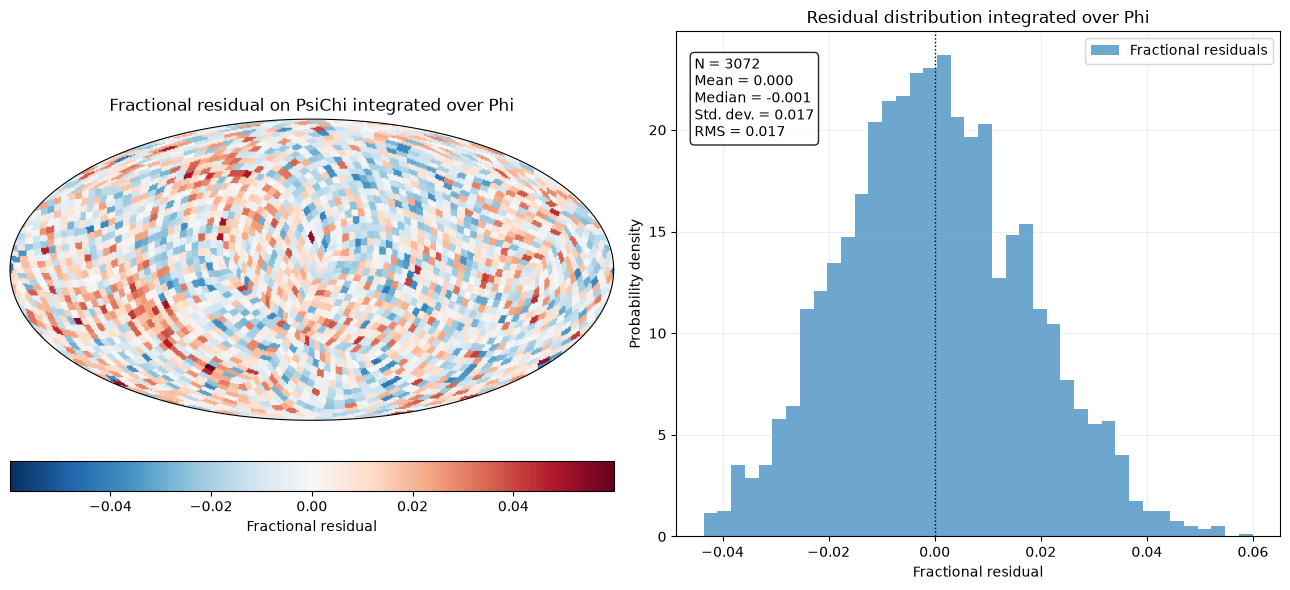

In [17]:
# Plot fractional residuals for the full PsiChi projection integrated over Phi.
psichi_fractional_figure = residual_plots.plot(
    "PsiChi_projection",
    residual_type="fractional",
)


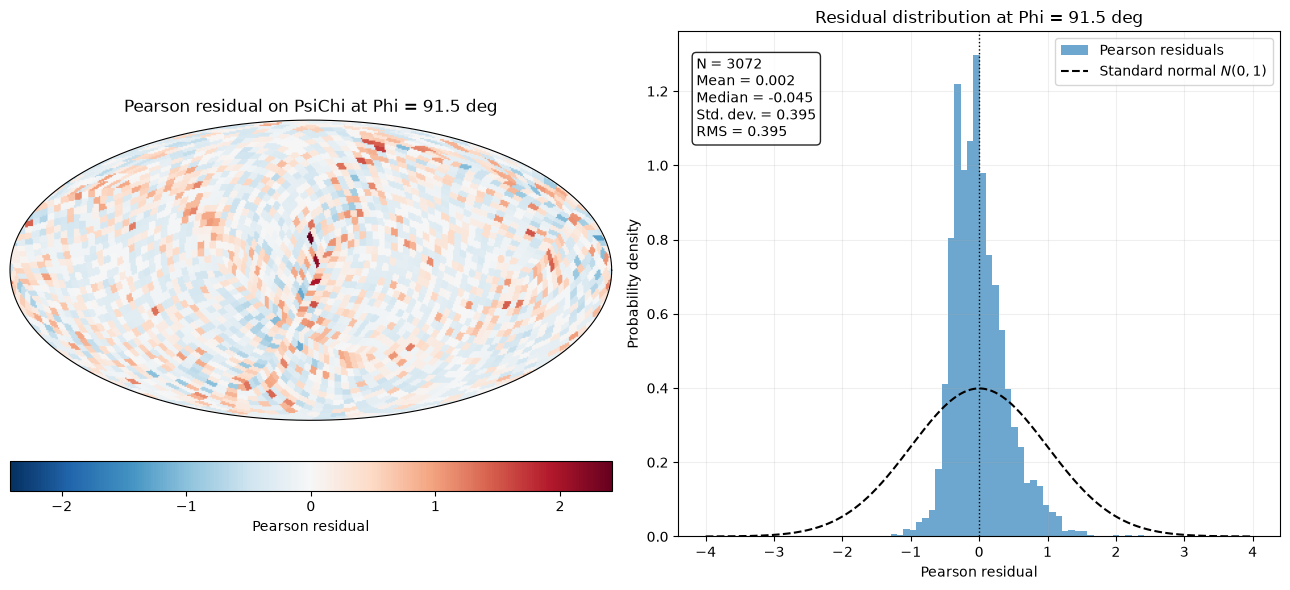

In [18]:
# Plot the PsiChi map for the Phi bin centered near 91.5 degrees.
phi_slice_pearson_figure = residual_plots.plot(
    "Phi_PsiChi_projection",
    residual_type="pearson",
    phi_bin_index=30,
)

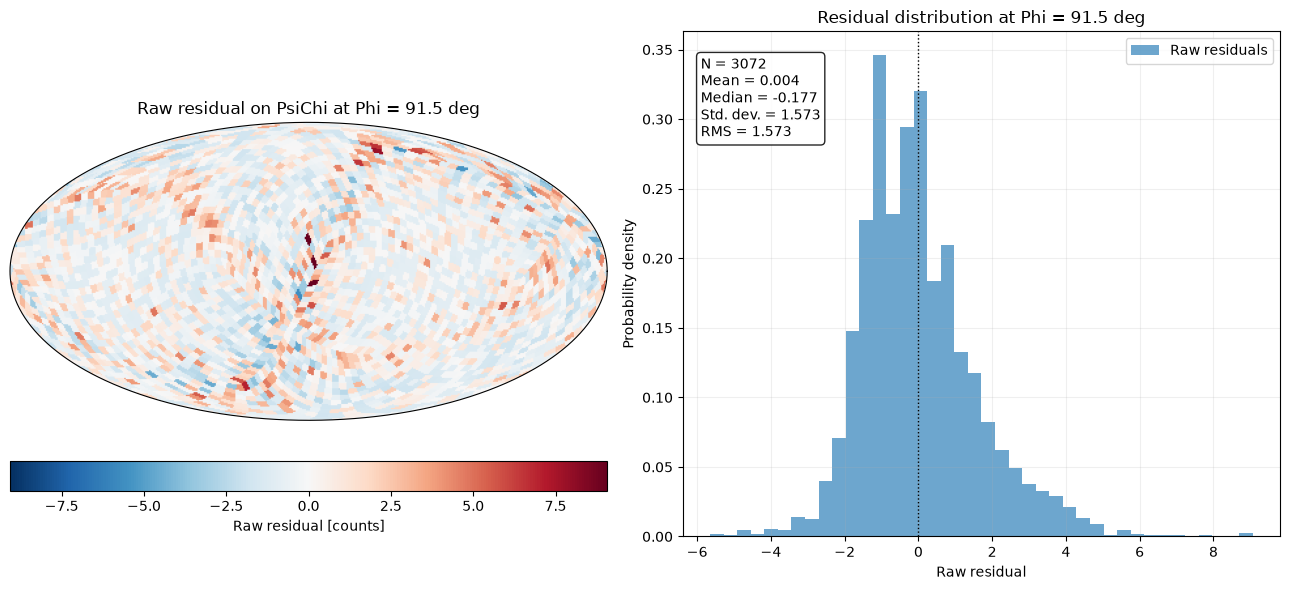

In [19]:
# Plot raw residuals for the PsiChi map at the selected Phi bin.
phi_slice_raw_figure = residual_plots.plot(
    "Phi_PsiChi_projection",
    residual_type="raw",
    phi_bin_index=30,
)

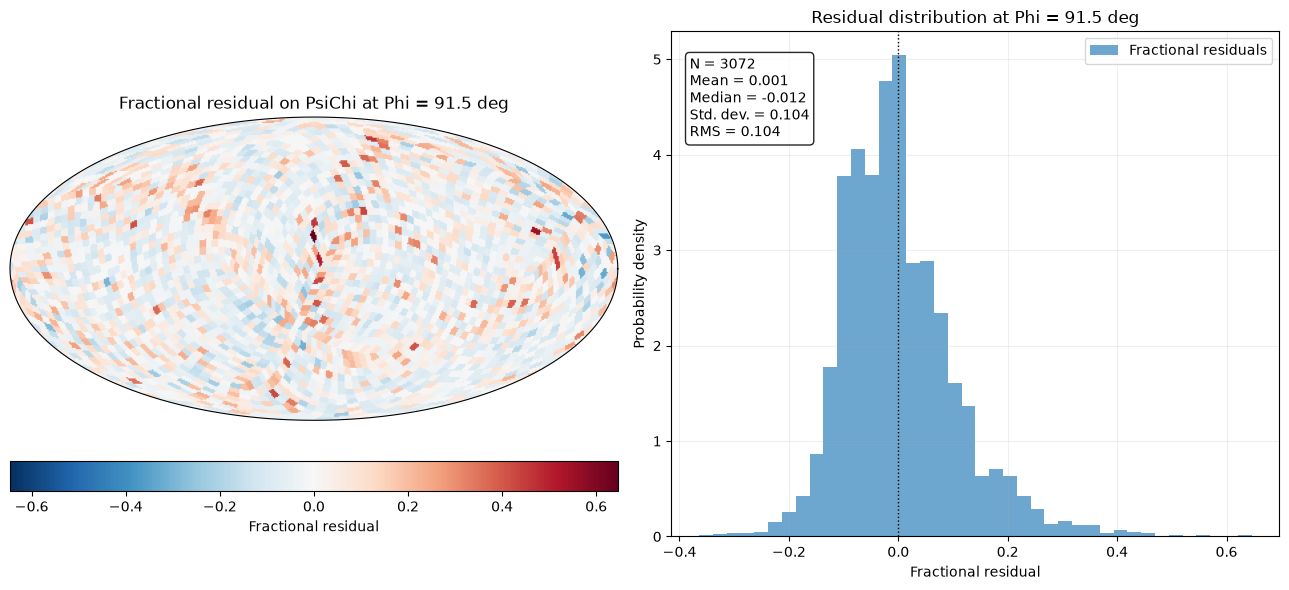

In [20]:
# Plot fractional residuals for the PsiChi map at the selected Phi bin.
phi_slice_fractional_figure = residual_plots.plot(
    "Phi_PsiChi_projection",
    residual_type="fractional",
    phi_bin_index=30,
)

## Fractional 2D view: interpret the color scale with care

Fractional residuals divide the observed-minus-expected difference by the expectation. A low-expectation bin can therefore have a large relative residual even when its absolute count difference is small. In this dataset, the largest Phi–Chi value is at Phi = 10.5 deg and Chi = 337.5 deg: 3 observed counts versus an expectation of about 0.312, giving a fractional residual near 8.62. For the maps, the shared color range is set by the 99.5th percentile of absolute residuals; values beyond that range saturate at the colorbar limits, while the distributions and statistics retain their full values. The low-count outlier is not, by itself, evidence of a physical feature.


In [21]:
# Find the Phi–Chi bin with the largest absolute fractional residual.

projection_products = residual_analysis.projected_data()["Phi_Chi_projection"]
fractional_hist = residual_analysis.residual_function(
    "Phi_Chi_projection",
    residual_type="fractional",
)
fractional_values = np.asarray(fractional_hist.contents, dtype=float)
bin_index = np.unravel_index(
    np.nanargmax(np.abs(fractional_values)),
    fractional_values.shape,
)

# Display the bin location and its observed, expected, and fractional values.
print("Bin index (Phi, Chi):", bin_index)
print("Phi center:", projection_products["observed"].axes["Phi"].centers[bin_index[0]])
print("Chi center:", projection_products["observed"].axes["Chi"].centers[bin_index[1]])
print("Observed:", projection_products["observed"].contents[bin_index])
print("Expected:", projection_products["expected"].contents[bin_index])
print("Fractional residual:", fractional_values[bin_index])

Bin index (Phi, Chi): (np.int64(3), np.int64(67))
Phi center: 10.5 deg
Chi center: 337.5 deg
Observed: 3.0
Expected: 0.3119865551228713
Fractional residual: 8.615798984730269


/Users/maura/Documents/COSI/data-challenge-4/workflow/src/plot_residuals.py:512: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()


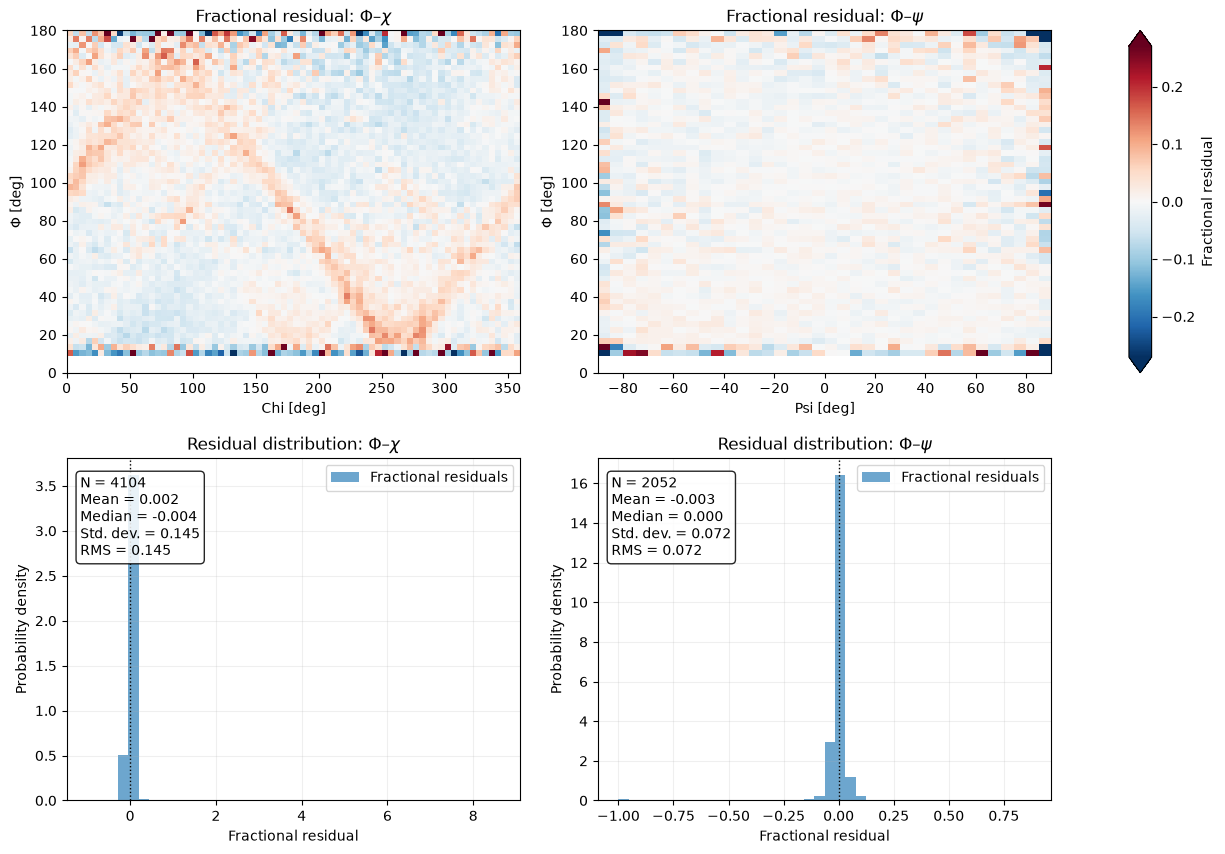

In [22]:
# Plot fractional residual diagnostics for the paired 2D projections.
phi_2d_fractional_figure = residual_plots.plot(
    "Phi_Chi_projection",
    residual_type="fractional",
)